CBOW model trained successfully!
Epoch 1/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8297 - loss: 0.3891 - val_accuracy: 0.8560 - val_loss: 0.3338
Epoch 2/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8522 - loss: 0.3436 - val_accuracy: 0.8634 - val_loss: 0.3279
Epoch 3/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8564 - loss: 0.3364 - val_accuracy: 0.8590 - val_loss: 0.3284
Epoch 4/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8583 - loss: 0.3324 - val_accuracy: 0.8537 - val_loss: 0.3409
Epoch 5/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8594 - loss: 0.3293 - val_accuracy: 0.8565 - val_loss: 0.3326
Epoch 6/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8607 - loss: 0.3266 - val_accuracy: 0.8553 - val_loss: 0.3355
Epoch 7/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8617 - loss: 0.3246 - val_accuracy: 0.8575 - val_loss: 0.3309
Epoch 8/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - a

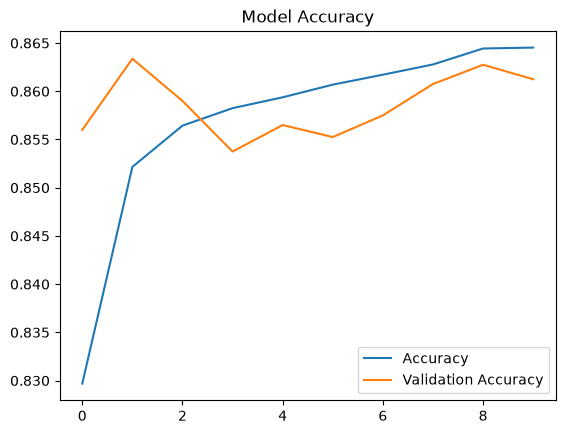

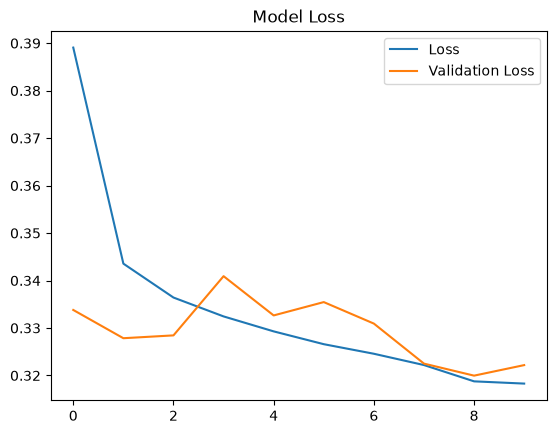

Sentiment: Positive


In [1]:

# Practical 4A: CBOW for Document Classification

# 1. Import libraries
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

# 2. Load dataset
data = pd.read_csv("IMDB Dataset.csv")

# Convert sentiment into numbers
data = data.dropna(subset=["review", "sentiment"])
labels = data["sentiment"].map({"positive": 1, "negative": 0}).values

# 3. Preprocess reviews
stop_words = {"the", "is", "a", "an", "and", "to", "of",
              "in", "it", "this", "that", "was", "for"}

def preprocess(text):
    text = re.sub("[^a-z ]", "", text.lower())
    return [word for word in text.split() if word not in stop_words]

sentences = data["review"].astype(str).apply(preprocess).tolist()

# 4. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    sentences, labels, test_size=0.2, random_state=42
)

# 5. Train CBOW Word2Vec model
cbow_model = Word2Vec(
    sentences=X_train,
    vector_size=100,
    window=5,
    min_count=2,
    sg=0,
    epochs=10
)

print("CBOW model trained successfully!")

# 6. Convert documents into average word embeddings
def get_document_vector(words):
    vectors = [cbow_model.wv[w] for w in words if w in cbow_model.wv]

    if len(vectors) == 0:
        return np.zeros(100)

    return np.mean(vectors, axis=0)

X_train_vectors = np.array([get_document_vector(x) for x in X_train])
X_test_vectors = np.array([get_document_vector(x) for x in X_test])

# 7. Build classification model
model = Sequential([
    Input(shape=(100,)),
    Dense(64, activation="relu"),
    Dense(1, activation="sigmoid")
])

# 8. Compile model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 9. Train model
history = model.fit(
    X_train_vectors, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

# 10. Evaluate model
loss, accuracy = model.evaluate(X_test_vectors, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# 11. Plot accuracy and loss
plt.plot(history.history["accuracy"], label="Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.title("Model Accuracy")
plt.show()

plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.title("Model Loss")
plt.show()

# 12. Test a sample review
sample = preprocess("This movie was amazing and I really enjoyed it")
sample_vector = get_document_vector(sample)

prediction = model.predict(np.array([sample_vector]), verbose=0)

print("Sentiment:", "Positive" if prediction[0][0] >= 0.5 else "Negative")


## Practical 4A – CBOW for Document Classification using Deep Learning

Problem statement: Implement CBOW for document classification using deep learning. Train a Word2Vec model using CBOW to generate word embeddings, average the embeddings to represent documents, and use a feed-forward neural network for classification.

### 1. Understand the practical

This practical uses movie reviews to predict whether a review is Positive or Negative.

Example:

- "This movie was amazing" → Positive.
- "This movie was boring" → Negative.

The model uses CBOW (Continuous Bag of Words) to learn word meanings and then uses those word embeddings to classify the entire review.

IMDB Movie Reviews

Movie review text

Text Preprocessing

Lowercase, remove symbols and stop words

CBOW Word2Vec

Learn word embeddings

Average Word Embeddings

Create document representation

Neural Network

Positive or Negative classification

### 2. Explanation of your code

Step 1 – Import libraries

```
import pandas as pdimport numpy as npimport reimport matplotlib.pyplot as pltfrom gensim.models import Word2Vecfrom sklearn.model_selection import train_test_splitfrom tensorflow.keras.models import Sequentialfrom tensorflow.keras.layers import Dense, Input
```

- Pandas: loads the review dataset.
- NumPy: numerical calculations.
- `re`: removes unwanted characters.
- Word2Vec: trains CBOW.
- train_test_split: divides training and testing data.
- TensorFlow: builds the classification model.

Step 2 – Load dataset

```
data = pd.read_csv("IMDB Dataset.csv")
```

Loads the IMDB movie review dataset.

It contains two important columns:

| Column      | Meaning              |
| ----------- | -------------------- |
| `review`    | Movie review text    |
| `sentiment` | Positive or negative |

```
data = data.dropna(subset=["review", "sentiment"])labels = data["sentiment"].map({    "positive": 1,    "negative": 0}).values
```

- `dropna()` removes missing reviews or labels.
- Positive is converted to `1`.
- Negative is converted to `0`.

Step 3 – Preprocess reviews

```
stop_words = {    "the", "is", "a", "an", "and", "to", "of",    "in", "it", "this", "that", "was", "for"}
```

Stop words are commonly occurring words that are often removed during text preprocessing.

```
def preprocess(text):    text = re.sub("[^a-z ]", "", text.lower())    return [word for word in text.split() if word not in stop_words]
```

Understand the three operations:

1. `lower()` converts text into lowercase.
2. `re.sub()` removes numbers and special characters.
3. `split()` separates sentences into words.
4. Stop words are removed.

Example:

`"This Movie is Amazing!"`

After preprocessing:

`["movie", "amazing"]`

Step 4 – Split dataset

```
X_train, X_test, y_train, y_test = train_test_split(    sentences, labels, test_size=0.2, random_state=42)
```

- 80% training data.
- 20% testing data.
- `random_state=42` makes the split reproducible.

Step 5 – Train CBOW Word2Vec

This is the most important part.

```
cbow_model = Word2Vec(    sentences=X_train,    vector_size=100,    window=5,    min_count=2,    sg=0,    epochs=10)
```

| Parameter         | Meaning                                  |
| ----------------- | ---------------------------------------- |
| `sentences`       | Training reviews                         |
| `vector_size=100` | Each word gets 100 numbers               |
| `window=5`        | Considers nearby context words           |
| `min_count=2`     | Ignores words appearing fewer than twice |
| `sg=0`            | Uses CBOW                                |
| `epochs=10`       | Trains for 10 iterations                 |

What is CBOW?

CBOW stands for Continuous Bag of Words.

It predicts a target word using the surrounding context words.

Example:

`I love this movie`

CBOW learns relationships between the surrounding words and the target word.

Simple CBOW example

I

love

movie

Predict target word: "this"

Remember:

- `sg=0` → CBOW.
- `sg=1` → Skip-gram.

Step 6 – Convert documents into word embeddings

```
def get_document_vector(words):    vectors = [        cbow_model.wv[w]        for w in words        if w in cbow_model.wv    ]    if len(vectors) == 0:        return np.zeros(100)    return np.mean(vectors, axis=0)
```

This function converts a complete review into a single vector.

For example:

- Word 1 → 100 numbers.
- Word 2 → 100 numbers.
- Word 3 → 100 numbers.

The function calculates the average of these word vectors.

The result is one document vector containing 100 numbers.

```
X_train_vectors = np.array([    get_document_vector(x) for x in X_train])
```

Converts all training reviews into vectors.

Step 7 – Build classification model

```
model = Sequential([    Input(shape=(100,)),    Dense(64, activation="relu"),    Dense(1, activation="sigmoid")])
```

| Layer      | Purpose                        |
| ---------- | ------------------------------ |
| Input(100) | Receives document vector       |
| Dense(64)  | Learns classification patterns |
| Dense(1)   | Predicts positive or negative  |

Step 8 – Compile model

```
model.compile(    optimizer="adam",    loss="binary_crossentropy",    metrics=["accuracy"])
```

- Adam: optimizer.
- Binary crossentropy: loss function for two-class classification.
- Accuracy: measures correct predictions.

Step 9 – Train model

```
history = model.fit(    X_train_vectors, y_train,    epochs=10,    batch_size=32,    validation_split=0.2)
```

- Epochs = 10.
- Batch size = 32.
- Validation split = 20%.

The model learns to classify reviews using their document vectors.

Step 10 – Evaluate model

```
loss, accuracy = model.evaluate(X_test_vectors, y_test)
```

Tests the trained model on unseen reviews and returns test loss and accuracy.

Step 11 – Plot accuracy and loss

The first graph shows training and validation accuracy.

The second graph shows training and validation loss.

These graphs help us understand how the model learns.

Step 12 – Test a sample review

```
sample = preprocess(    "This movie was amazing and I really enjoyed it")sample_vector = get_document_vector(sample)prediction = model.predict(    np.array([sample_vector]), verbose=0)
```

The review is preprocessed, converted into a 100-dimensional vector, and passed to the classifier.

```
print(    "Sentiment:",    "Positive" if prediction[0][0] >= 0.5 else "Negative")
```

- Prediction ≥ 0.5 → Positive.
- Prediction below 0.5 → Negative.

### 3. Important viva questions

Q1. What is CBOW?

CBOW stands for Continuous Bag of Words. It predicts a target word using surrounding context words.

Q2. What is Word2Vec?

Word2Vec is a technique that converts words into numerical vectors called word embeddings.

Q3. What is the difference between CBOW and Skip-gram?

- CBOW predicts the target word from context words.
- Skip-gram predicts context words from the target word.

Q4. What is an embedding?

A numerical representation of a word that captures its meaning and relationships.

Q5. Why do we average word embeddings?

To convert all the word vectors in a review into one fixed-size document vector.

Q6. What is `vector_size=100`?

Every word is represented using 100 numerical values.

Q7. What is `window=5`?

It specifies the context window size used by Word2Vec.

Q8. What is `sg=0`?

It selects the CBOW architecture.

Q9. Why do we use Sigmoid?

It produces a probability between 0 and 1 for binary classification.

Q10. What is Binary Crossentropy?

It is a loss function used for binary classification problems.

### 4. What to tell the examiner

"I implemented document classification using CBOW and deep learning on the IMDB movie review dataset. First, I loaded the reviews and converted sentiment labels into numerical values. Then I performed text preprocessing by converting text to lowercase and removing special characters and stop words. I trained a Word2Vec model using CBOW with sg equal to zero. Next, I converted each review into a document vector by averaging its word embeddings. Finally, I trained a feed-forward neural network to classify reviews as positive or negative and evaluated it using test accuracy and loss."

### 5. Quick revision

| Parameter               | Value                    |
| ----------------------- | ------------------------ |
| Dataset                 | IMDB                     |
| Task                    | Sentiment classification |
| Architecture            | CBOW + Feed-forward NN   |
| Word2Vec                | CBOW (`sg=0`)            |
| Vector size             | 100                      |
| Window                  | 5                        |
| Minimum word count      | 2                        |
| Encoder/document vector | Average embeddings       |
| Dense layer             | 64 neurons               |
| Output                  | 1 neuron                 |
| Optimizer               | Adam                     |
| Loss                    | Binary crossentropy      |
| Epochs                  | 10                       |
| Batch size              | 32                       |

Important to remember

CBOW → Word Embeddings → Average Embeddings → Neural Network → Sentiment Prediction.

Your code follows the practical's main workflow. One technical improvement: your `re.sub()` preprocessing removes the word `"not"` only if it is not in the stop-word set; currently it is retained, which is good because removing negation can change sentiment. Also, Word2Vec is trained only on training reviews, avoiding test-data leakage.